## Caso Bellabeat

### OBJETIVO

 Identificar oportunidades para aumentar la retención de usuarios y el engagement con la aplicación Bellabeat a través del análisis detallado de los datos de uso de los dispositivos inteligentes.

Alcance:

Problema: Baja tasa de retención de usuarios a largo plazo en la aplicación Bellabeat.

Interesados clave: Equipo de producto, equipo de marketing, equipo de desarrollo, cofundadores (Urška Sršen y Sando Mur).

Enfoque: Analizar los datos de uso de los dispositivos Leaf, Time y Spring para identificar patrones de comportamiento que puedan explicar la baja retención y proponer estrategias de mejora.

Empresa: Bellabeat, una empresa de tecnología enfocada en el bienestar femenino.

Producto a analizar: Uno de los dispositivos inteligentes de Bellabeat (Leaf, Time, Spring).

Objetivo final: Informar a la dirección de Bellabeat sobre las tendencias de uso de los dispositivos y proponer estrategias de marketing basadas en los datos

### Enfoque

Análisis exploratorio: Identificar patrones, tendencias y anomalías en los datos de uso.

Segmentación de usuarios: Dividir a los usuarios en grupos basados en sus características y comportamientos.

Visualización de datos: Crear gráficos y dashboards para comunicar los hallazgos de manera clara y concisa.

### Como recolecta los datos Bellabeat?

"A través de dispositivos inteligentes recopila datos sobre diversos aspectos de la salud femenina, como el sueño, la actividad física y el ciclo menstrual, Bellabeat ofrece herramientas y conocimientos personalizados para mejorar el bienestar general."


 App: Bellabeat
 
Dispositivos:

Brazalete: Leaf

Smartwatch: Time

Botella de agua: Spring

### Carga de datos y librerias

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/heartrate_seconds_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlyCalories_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlyIntensities_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlySteps_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteCaloriesNarrow_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteIntensitiesNarrow_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteMETsNarrow_merged.csv
/kaggle/input/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16

In [2]:
import numpy as np
import pandas as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/kaggle/input/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyActivity_merged.csv')
df.head(5)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,4/12/2016,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985
1,1503960366,4/13/2016,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797
2,1503960366,4/14/2016,10460,6.74,6.74,0.0,2.44,0.40,3.91,0.0,30,11,181,1218,1776
3,1503960366,4/15/2016,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745
4,1503960366,4/16/2016,12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863


## Limpiez  y Calidad de Datos

### Ampliación de la descripción de las herramientas:

Especificar versiones: Las herramientas utilizadas (pPython 3.9, Pandas 1.4.2). 

Justificacion de la  elección: Se utilizó Python debido a su amplia gama de librerías para análisis de datos (Pandas, NumPy) y su comunidad activa.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 940 entries, 0 to 939
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        940 non-null    int64  
 1   ActivityDate              940 non-null    object 
 2   TotalSteps                940 non-null    int64  
 3   TotalDistance             940 non-null    float64
 4   TrackerDistance           940 non-null    float64
 5   LoggedActivitiesDistance  940 non-null    float64
 6   VeryActiveDistance        940 non-null    float64
 7   ModeratelyActiveDistance  940 non-null    float64
 8   LightActiveDistance       940 non-null    float64
 9   SedentaryActiveDistance   940 non-null    float64
 10  VeryActiveMinutes         940 non-null    int64  
 11  FairlyActiveMinutes       940 non-null    int64  
 12  LightlyActiveMinutes      940 non-null    int64  
 13  SedentaryMinutes          940 non-null    int64  
 14  Calories  

In [5]:
df['ActivityDate'] = pd.to_datetime(df['ActivityDate'])
df.dtypes

Id                                   int64
ActivityDate                datetime64[ns]
TotalSteps                           int64
TotalDistance                      float64
TrackerDistance                    float64
LoggedActivitiesDistance           float64
VeryActiveDistance                 float64
ModeratelyActiveDistance           float64
LightActiveDistance                float64
SedentaryActiveDistance            float64
VeryActiveMinutes                    int64
FairlyActiveMinutes                  int64
LightlyActiveMinutes                 int64
SedentaryMinutes                     int64
Calories                             int64
dtype: object

## Valores Unicos

In [6]:
df.nunique().sort_values()

SedentaryActiveDistance       9
LoggedActivitiesDistance     19
ActivityDate                 31
Id                           33
FairlyActiveMinutes          81
VeryActiveMinutes           122
ModeratelyActiveDistance    211
VeryActiveDistance          333
LightlyActiveMinutes        335
LightActiveDistance         491
SedentaryMinutes            549
TrackerDistance             613
TotalDistance               615
Calories                    734
TotalSteps                  842
dtype: int64

### Registros duplicados

In [7]:
df.duplicated().sum()

0

### Valores Nulos

In [8]:
df.isna().sum().sort_values()

Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64

## Analisis de Variables

### Analisis Estadisticos

In [9]:
def estadisticos_cont(df):
  estadisticos = df.describe().T
  estadisticos['median'] = df.median()
  return(estadisticos)

In [10]:
estadisticos_cont(df)

,count,mean,min,25%,50%,75%,max,std,median
Id,940.0,4855407369.332978,1503960366.0,2320127002.0,4445114986.0,6962181067.0,8877689391.0,2424805475.65796,4445114986.0
ActivityDate,940,2016-04-26 06:53:37.021276672,2016-04-12 00:00:00,2016-04-19 00:00:00,2016-04-26 00:00:00,2016-05-04 00:00:00,2016-05-12 00:00:00,NaN,2016-04-26 00:00:00
TotalSteps,940.0,7637.910638,0.0,3789.75,7405.5,10727.0,36019.0,5087.150742,7405.5
TotalDistance,940.0,5.489702,0.0,2.62,5.245,7.7125,28.030001,3.924606,5.245
TrackerDistance,940.0,5.475351,0.0,2.62,5.245,7.71,28.030001,3.907276,5.245
LoggedActivitiesDistance,940.0,0.108171,0.0,0.0,0.0,0.0,4.942142,0.619897,0.0
VeryActiveDistance,940.0,1.502681,0.0,0.0,0.21,2.0525,21.92,2.658941,0.21
ModeratelyActiveDistance,940.0,0.567543,0.0,0.0,0.24,0.8,6.48,0.88358,0.24
LightActiveDistance,940.0,3.340819,0.0,1.945,3.365,4.7825,10.71,2.040655,3.365
SedentaryActiveDistance,940.0,0.001606,0.0,0.0,0.0,0.0,0.11,0.007346,0.0


In [11]:
num = df.loc[:, 'TotalSteps':]
num


,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,13162,8.500000,8.500000,0.0,1.88,0.55,6.06,0.00,25,13,328,728,1985
1,10735,6.970000,6.970000,0.0,1.57,0.69,4.71,0.00,21,19,217,776,1797
2,10460,6.740000,6.740000,0.0,2.44,0.40,3.91,0.00,30,11,181,1218,1776
3,9762,6.280000,6.280000,0.0,2.14,1.26,2.83,0.00,29,34,209,726,1745
4,12669,8.160000,8.160000,0.0,2.71,0.41,5.04,0.00,36,10,221,773,1863
...,...,...,...,...,...,...,...,...,...,...,...,...,...
935,10686,8.110000,8.110000,0.0,1.08,0.20,6.80,0.00,17,4,245,1174,2847
936,20226,18.250000,18.250000,0.0,11.10,0.80,6.24,0.05,73,19,217,1131,3710
937,10733,8.150000,8.150000,0.0,1.35,0.46,6.28,0.00,18,11,224,1187,2832
938,21420,19.559999,19.559999,0.0,13.22,0.41,5.89,0.00,88,12,213,1127,3832


In [12]:
import matplotlib.pyplot as plt
from math import ceil

def graficos_eda_continuas(num):
    filas = ceil(num.shape[1] / 2) 
    f, ax = plt.subplots(nrows=filas, ncols=2, figsize=(18, filas * 7)) 
    ax = ax.flat  

    for cada, variable in enumerate(num):
        # Personalización de la densidad
        num[variable].plot.density(
            ax=ax[cada], 
            color="coral", 
            linewidth=3  
        )
        
        # Personalización del título
        ax[cada].set_title(
            variable, 
            fontsize=16,  
            fontweight='bold',  
            color='navy'  
        )
        
        # Personalización de los ticks
        ax[cada].tick_params(
            labelsize=14,  
            labelcolor='darkgreen'  
        )
        
        # Activar cuadrícula personalizada
        ax[cada].grid(
            linestyle='--', 
            color='gray',  
            alpha=0.6  
        )
    
    # Eliminar ejes vacíos si el número de gráficos es impar
    for i in range(cada + 1, len(ax)):
        f.delaxes(ax[i])

 
    plt.tight_layout()
    plt.show()


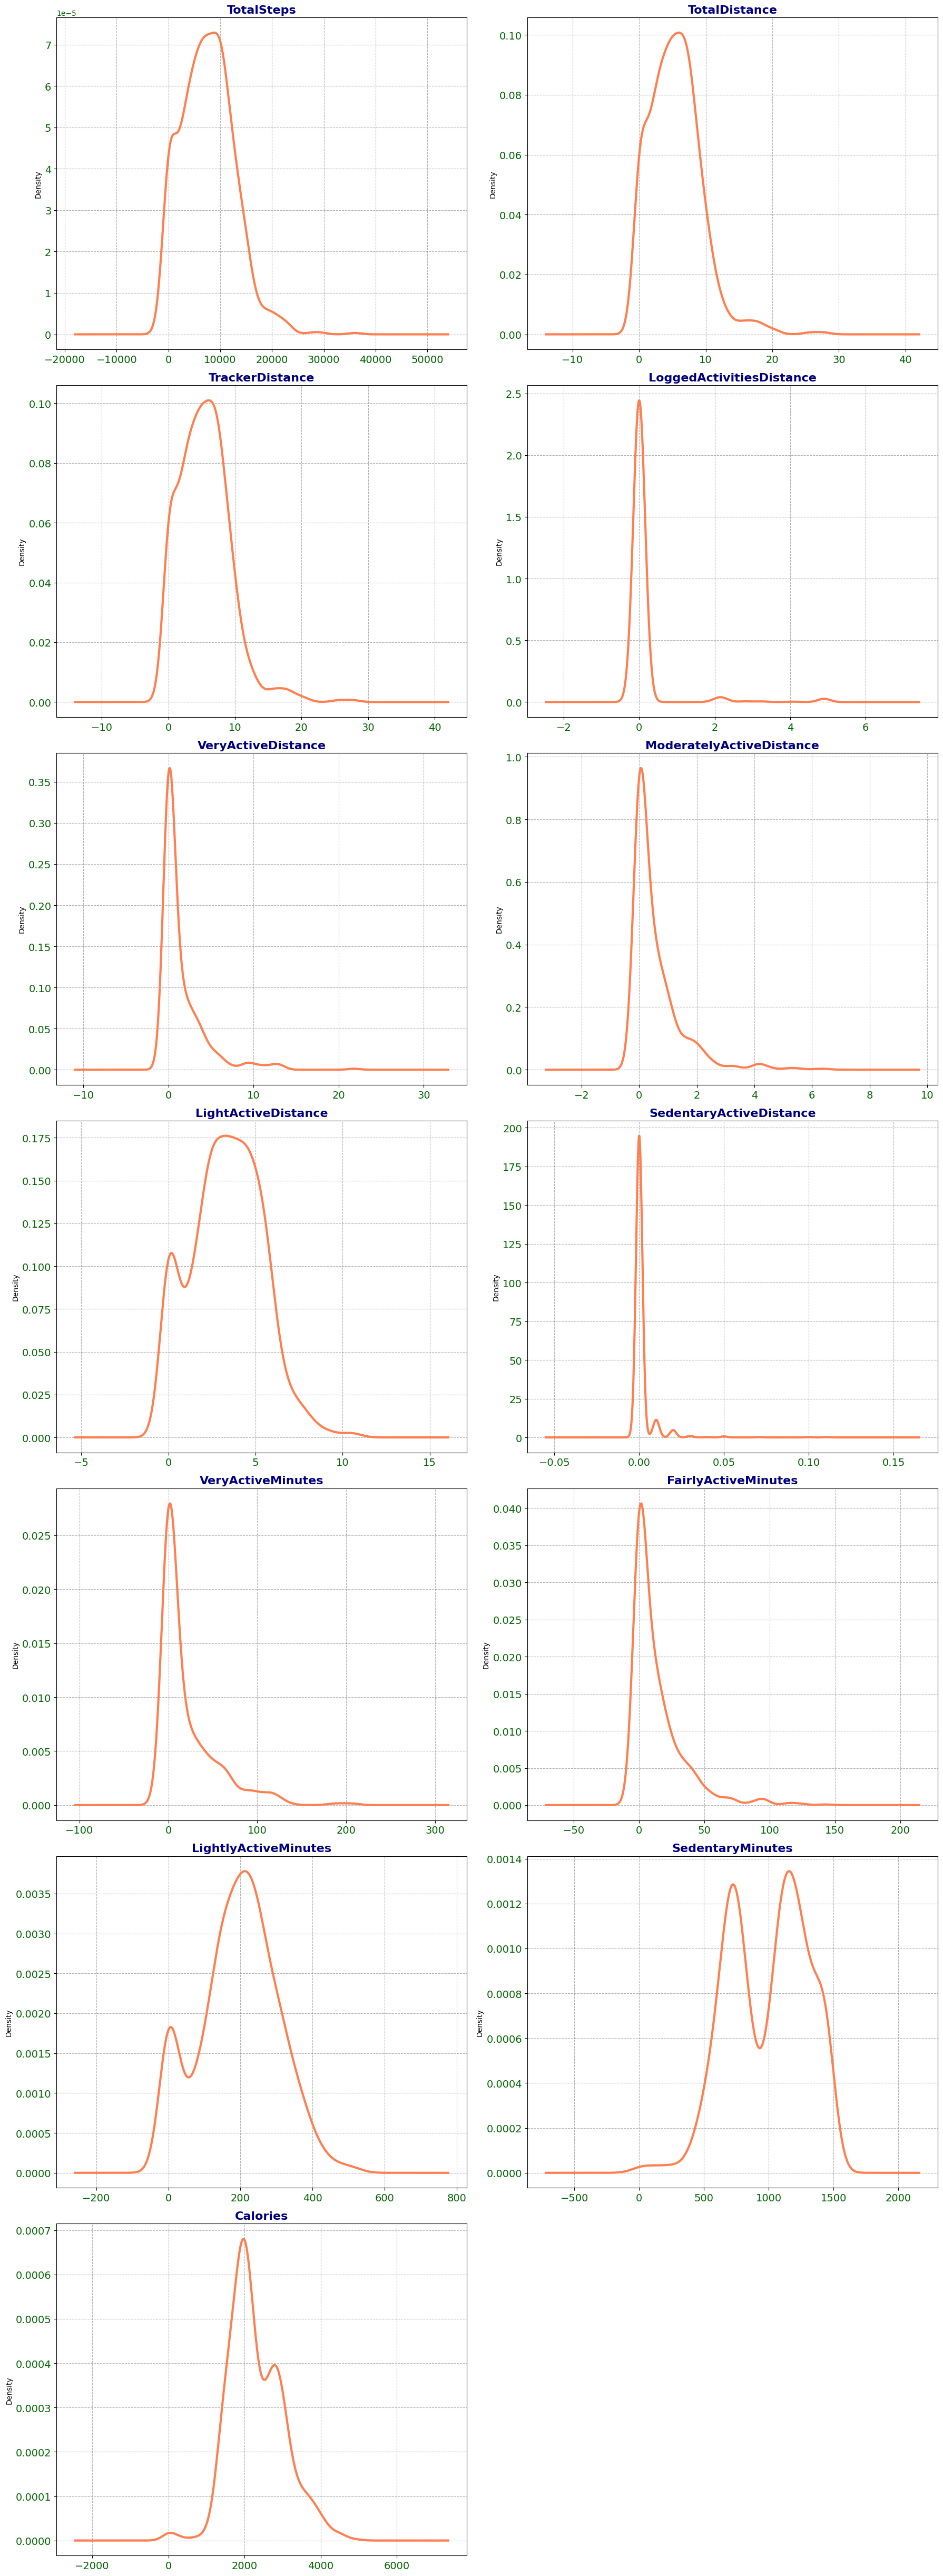

In [13]:
graficos_eda_continuas(num)

## Segmentacion

### Calorias

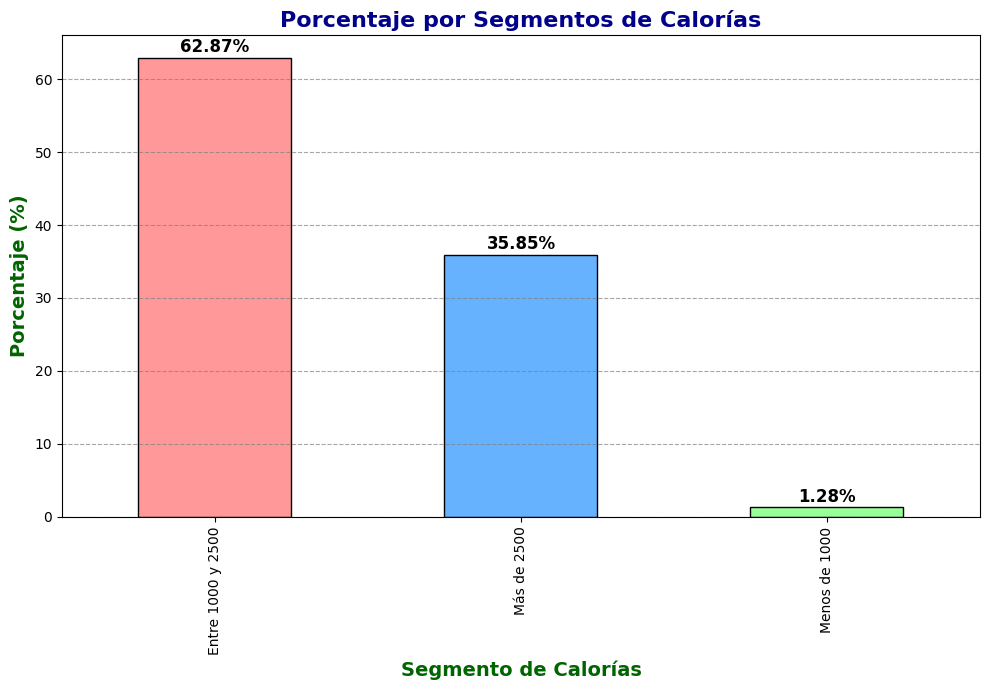

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# Definimos las categorías personalizadas
bins = [float('-inf'), 1000, 2500, float('inf')]
labels = ['Menos de 1000', 'Entre 1000 y 2500', 'Más de 2500']
df['calorias_segmentadas'] = pd.cut(df['Calories'], bins=bins, labels=labels, include_lowest=True)

# Calculamos los porcentajes
categoria_porcentajes = df['calorias_segmentadas'].value_counts(normalize=True) * 100

# Personalizamos el diseño del gráfico
plt.figure(figsize=(10, 7))  
categoria_porcentajes.plot(
    kind='bar', 
    color=['#FF9999', '#66B2FF', '#99FF99'],  
    edgecolor='black' 
)

# Personalización de títulos y etiquetas
plt.title('Porcentaje por Segmentos de Calorías', fontsize=16, fontweight='bold', color='darkblue')
plt.xlabel('Segmento de Calorías', fontsize=14, fontweight='bold', color='darkgreen')
plt.ylabel('Porcentaje (%)', fontsize=14, fontweight='bold', color='darkgreen')

# Personalización de la cuadrícula
plt.grid(
    axis='y',  
    linestyle='--',  
    color='gray',  
    alpha=0.7  
)

# Añadimos los valores encima de las barras
for index, value in enumerate(categoria_porcentajes):
    plt.text(
        index, 
        value + 0.8,  
        f'{value:.2f}%', 
        ha='center', 
        color='black', 
        fontsize=12, 
        fontweight='bold'
    )

# Ajustamos los márgenes
plt.tight_layout()
plt.show()

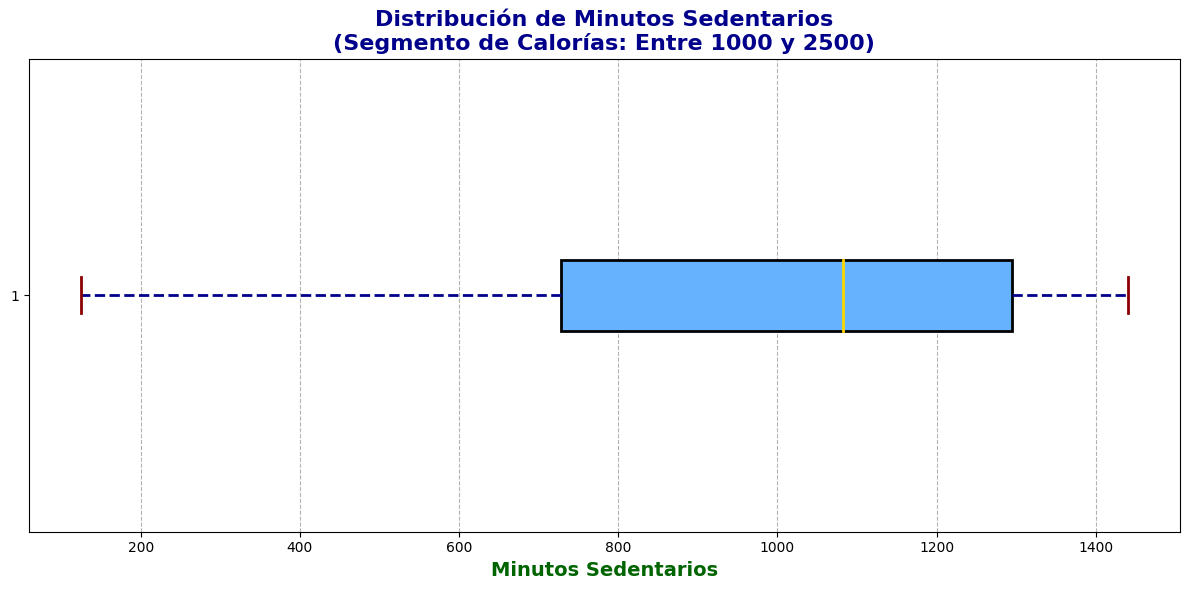

In [15]:
import matplotlib.pyplot as plt

# Filtrar los datos según la condición
filtro_sedentarios = df[(df['calorias_segmentadas'] == 'Entre 1000 y 2500')]['SedentaryMinutes']

# Crear el gráfico de caja con personalización
plt.figure(figsize=(12, 6))  
box = plt.boxplot(
    filtro_sedentarios, 
    vert=False,  
    patch_artist=True,  
    boxprops=dict(facecolor='#66B2FF', color='black', linewidth=2),  
    whiskerprops=dict(color='darkblue', linewidth=2, linestyle='--'), 
    capprops=dict(color='darkred', linewidth=2),  
    medianprops=dict(color='gold', linewidth=2),  
    flierprops=dict(marker='o', color='red', markersize=8, alpha=0.7)  
)

# Personalización de los títulos y etiquetas
plt.title('Distribución de Minutos Sedentarios\n(Segmento de Calorías: Entre 1000 y 2500)', 
          fontsize=16, fontweight='bold', color='darkblue')
plt.xlabel('Minutos Sedentarios', fontsize=14, fontweight='bold', color='darkgreen')
plt.grid(axis='x', linestyle='--', alpha=0.6, color='gray')  

# Ajuste del diseño
plt.tight_layout()
plt.show()

## ACTUAR

### Recomendaciones de contenido de alto nivel basadas en el análisis

La gráfica muestra un claro sesgo hacia un rango específico de consumo calórico entre los usuarios de los dispositivos Bellabeat. La mayoría de los usuarios se encuentran en el rango de entre 1000 y 2500 calorías diarias, lo que sugiere un perfil de usuario que busca un equilibrio en su alimentación y actividad física.

La gráfica de caja y bigotes nos proporciona una visión general de la distribución de los minutos sedentarios entre los usuarios de Bellabeat que consumen entre 1000 y 2500 calorías diarias, la gráfica de minutos sedentarios nos proporciona una valiosa información adicional que nos permite ajustar nuestra estrategia de marketing y ofrecer un valor aún mayor a los usuarios de Bellabeat. Al combinar los datos de consumo calórico con los niveles de actividad sedentaria, podemos crear experiencias más personalizadas y relevantes para cada usuario.

Nuestro análisis de los datos de uso de los dispositivos Bellabeat reveló patrones interesantes en el comportamiento de los usuarios. Observamos un claro sesgo hacia un rango específico de consumo calórico (1000-2500 calorías diarias), lo que sugiere un perfil de usuario que busca un equilibrio entre salud y disfrute.

Al cruzar estos datos con los niveles de actividad sedentaria, identificamos una oportunidad significativa: muchos usuarios dentro de este rango de consumo calórico presentan altos niveles de sedentarismo. Esta combinación sugiere una necesidad de contenido y herramientas que les ayuden a incorporar más movimiento en su rutina diaria.

Tendencias de Uso de Dispositivos Inteligentes y su Aplicación a Bellabeat
Tendencias:

Enfoque en el bienestar: Los usuarios buscan dispositivos que les ayuden a llevar un estilo de vida más saludable y equilibrado.

Personalización: Los usuarios desean productos y servicios que se adapten a sus necesidades individuales.
Integración: Los dispositivos se integran cada vez más en la vida diaria de los usuarios, conectándose con otras aplicaciones y servicios.

Aplicación a Bellabeat:

Contenido educativo personalizado:

1 -Planes de actividad física: Ofrecer planes de ejercicio personalizados basados en el nivel de actividad sedentaria de cada usuario.
Consejos para reducir el sedentarismo: Proporcionar consejos prácticos para incorporar más movimiento en la rutina diaria, como estiramientos en la oficina o pausas activas.
Historias de éxito:

2- Casos de estudio: Destacar historias de usuarios que han logrado reducir sus niveles de sedentarismo y mejorar su salud.
Testimonios: Compartir testimonios de usuarios que han encontrado beneficio en las herramientas de Bellabeat para mantenerse activos.
Marketing de influencia:

3 -Colaboraciones con expertos en fitness: Asociarse con entrenadores personales y fisioterapeutas para crear contenido de valor sobre cómo combatir el sedentarismo.
Influencers fitness: Colaborar con influencers que promuevan la actividad física y un estilo de vida saludable.


### Nuevas ideas para datos adicionales a analizar

Datos de uso de funciones específicas:

Seguimiento detallado: Analizar qué funciones de la aplicación utilizan con mayor frecuencia los usuarios de cada segmento.
Correlación con objetivos: Identificar si el uso de ciertas funciones se correlaciona con la consecución de objetivos específicos (por ejemplo, pérdida de peso, mejora del sueño).
Optimización de la experiencia: Utilizar esta información para optimizar el diseño de la aplicación y mejorar la experiencia del usuario.
Datos de interacción con notificaciones:

Tasa de apertura: Analizar la tasa de apertura de diferentes tipos de notificaciones (promociones, recordatorios de actividad, etc.).
Contenido más efectivo: Identificar el tipo de contenido que genera mayor engagement y mejores resultados.
Optimización de la frecuencia: Ajustar la frecuencia y el momento de envío de las notificaciones para maximizar su impacto.
Datos de integración con otras aplicaciones:

Aplicaciones más populares: Identificar las aplicaciones con las que Bellabeat se integra con mayor frecuencia.
Sinergias: Analizar si existe alguna sinergia entre el uso de Bellabeat y otras aplicaciones (por ejemplo, aplicaciones de nutrición, meditación).
Nuevas oportunidades de integración: Explorar nuevas oportunidades de integración con otras aplicaciones para ampliar el ecosistema de Bellabeat.
Datos de redes sociales:

Sentimiento del cliente: Analizar el sentimiento de los usuarios en las redes sociales hacia la marca Bellabeat y sus productos.
Temas más discutidos: Identificar los temas más relevantes para la comunidad de usuarios.
Influencers clave: Identificar a los influencers más relevantes en el sector de la salud y el bienestar.
Datos geográficos:

Preferencias regionales: Identificar si existen diferencias en las preferencias de los usuarios según su ubicación geográfica.
Clima y actividad física: Analizar la relación entre las condiciones climáticas y los niveles de actividad física de los usuarios.
Campañas de marketing localizadas: Desarrollar campañas de marketing más segmentadas y personalizadas en función de las características de cada región